# EC2 report: tables and plots
Every number in the report comes from the CSV files in `results/` (written by `delivery_sim --bench`). CPU and GPU were measured on the same laptop.

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CPU_MACHINE = 'laptop'     # the machine whose CPU columns go into the verdict
GPU_MACHINE = 'laptop'     # the machine whose GPU columns go into the verdict
df = pd.concat([pd.read_csv(f) for f in glob.glob('../results/bench_*.csv')], ignore_index=True)
print(df.machine.unique(), len(df), 'rows')
assert (df.correct == 'yes').all(), df[df.correct != 'yes']
APPS = list(dict.fromkeys(df.app))
med = df.groupby(['machine', 'app', 'concept', 'size', 'size_label', 'version', 'threads']).ms.agg(
    median='median', lo='min', hi='max').reset_index()
med.head()

<StringArray>
['laptop']
Length: 1, dtype: str 3250 rows


,machine,app,concept,size,size_label,version,threads,median,lo,hi
0,laptop,argmin,08_reduction,500,10x50,cpu1,1,0.00110,0.0009,0.0021
1,laptop,argmin,08_reduction,500,10x50,cpuN,1,0.13755,0.0809,2.0978
2,laptop,argmin,08_reduction,500,10x50,cpuN,2,0.17065,0.1026,0.4530
3,laptop,argmin,08_reduction,500,10x50,cpuN,4,0.23745,0.1917,0.5811
4,laptop,argmin,08_reduction,500,10x50,cpuN,8,0.39300,0.2962,0.5237


## Table per application (CPU and GPU on the laptop)

In [2]:
def table(app, cpu_machine=CPU_MACHINE, gpu_machine=GPU_MACHINE):
    m = med[med.app == app]
    cpu, gpu = m[m.machine == cpu_machine], m[m.machine == gpu_machine]
    rows = []
    for size, label in m[['size', 'size_label']].drop_duplicates().sort_values('size').values:
        c, g = cpu[cpu['size'] == size], gpu[gpu['size'] == size]
        one = c[c.version == 'cpu1']['median'].min()
        multi = c[c.version == 'cpuN'].sort_values('median').head(1)
        best = min(one, multi['median'].min()) if len(multi) else one
        k = g[g.version == 'gpu_kernel']['median'].min()
        e = g[g.version == 'gpu_e2e']['median'].min()
        rows.append({'size': label, 'CPU 1 (ms)': one,
                     f"CPU N={int(multi.threads.iloc[0]) if len(multi) else '-'} (ms)": multi['median'].min(),
                     'GPU kernel (ms)': k, 'GPU e2e (ms)': e,
                     'speedup kernel': best / k, 'speedup e2e': best / e, 'correct': 'yes'})
    return pd.DataFrame(rows)

for app in APPS:
    print(app)
    display(table(app).round(3))

conv


,size,CPU 1 (ms),CPU N=2 (ms),GPU kernel (ms),GPU e2e (ms),speedup kernel,speedup e2e,correct,CPU N=4 (ms),CPU N=20 (ms)
0,20m 95x136,0.260,0.267,0.015,0.691,17.082,0.377,yes,NaN,NaN
1,10m 190x271,1.030,NaN,0.016,0.770,28.375,0.604,yes,0.465,NaN
2,5m 380x542,4.270,NaN,0.015,1.397,91.071,1.004,yes,1.402,NaN
3,2m 949x1354,25.806,NaN,0.079,3.537,63.134,1.408,yes,NaN,4.978
4,1m 1898x2707,102.811,NaN,0.269,7.793,58.984,2.038,yes,NaN,15.884


hist


,size,CPU 1 (ms),CPU N=1 (ms),GPU kernel (ms),GPU e2e (ms),speedup kernel,speedup e2e,correct,CPU N=2 (ms),CPU N=4 (ms),CPU N=20 (ms)
0,10000,0.026,0.167,0.016,0.883,1.627,0.029,yes,NaN,NaN,NaN
1,100000,0.254,NaN,0.008,1.301,31.018,0.196,yes,0.276,NaN,NaN
2,1000000,2.625,NaN,0.025,2.710,45.415,0.412,yes,NaN,1.117,NaN
3,10000000,28.130,NaN,0.199,11.446,37.357,0.650,yes,NaN,NaN,7.442
4,32000000,81.856,NaN,0.624,24.560,28.099,0.713,yes,NaN,NaN,17.523


stencil


,size,CPU 1 (ms),CPU N=1 (ms),GPU kernel (ms),GPU e2e (ms),speedup kernel,speedup e2e,correct,CPU N=2 (ms),CPU N=20 (ms)
0,20m 95x136,2.379,2.462,0.841,2.021,2.828,1.177,yes,NaN,NaN
1,10m 190x271,9.331,NaN,0.895,2.079,7.321,3.152,yes,6.552,NaN
2,5m 380x542,36.756,NaN,1.404,3.506,15.013,6.011,yes,21.076,NaN
3,2m 949x1354,228.675,NaN,5.729,10.942,10.903,5.709,yes,NaN,62.466
4,1m 1898x2707,924.235,NaN,211.447,238.362,0.988,0.876,yes,NaN,208.815


... (4 outputs left out)

eta


,size,CPU 1 (ms),CPU N=1 (ms),GPU kernel (ms),GPU e2e (ms),speedup kernel,speedup e2e,correct,CPU N=4 (ms),CPU N=14 (ms),CPU N=20 (ms)
0,10x50,0.005,0.089,0.011,0.577,0.418,0.008,yes,NaN,NaN,NaN
1,100x500,0.350,NaN,0.020,0.698,13.767,0.395,yes,0.275,NaN,NaN
2,500x2000,8.255,NaN,0.080,2.209,27.183,0.983,yes,NaN,2.172,NaN
3,1000x5000,38.822,NaN,0.341,5.321,19.593,1.257,yes,NaN,NaN,6.690
4,2000x5000,90.061,NaN,0.665,25.748,45.856,1.184,yes,NaN,NaN,30.497


argmin


,size,CPU 1 (ms),CPU N=1 (ms),GPU kernel (ms),GPU e2e (ms),speedup kernel,speedup e2e,correct,CPU N=2 (ms),CPU N=4 (ms)
0,10x50,0.001,0.138,0.028,1.474,0.039,0.001,yes,NaN,NaN
1,100x500,0.062,NaN,0.013,1.653,4.669,0.038,yes,0.170,NaN
2,500x2000,1.266,NaN,0.024,2.995,34.299,0.270,yes,0.809,NaN
3,1000x5000,6.809,NaN,0.089,7.772,24.052,0.276,yes,NaN,2.143
4,2000x5000,13.840,NaN,0.170,11.484,24.584,0.365,yes,NaN,4.192


## Plot 1: time vs size (log-log) with the crossover

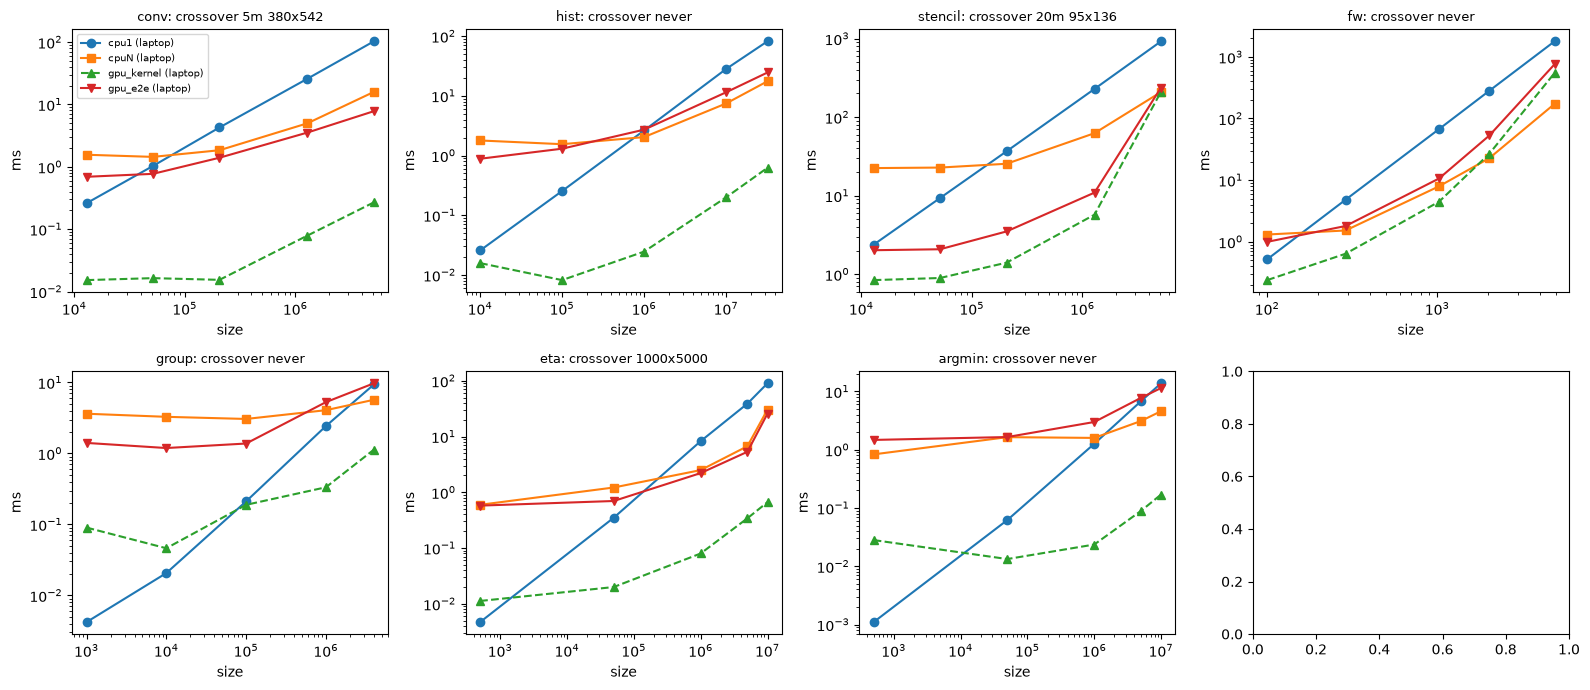

In [3]:
def crossover(app):
    t = table(app)
    best = t[[c for c in t.columns if c.startswith('CPU')]].min(axis=1)
    wins = t[t['GPU e2e (ms)'] < best]
    return wins['size'].iloc[0] if len(wins) else 'never'

fig, axes = plt.subplots(2, (len(APPS) + 1) // 2, figsize=(4 * ((len(APPS) + 1) // 2), 7))
for ax, app in zip(axes.flat, APPS):
    m = med[med.app == app]
    for machine, version, style in [(CPU_MACHINE, 'cpu1', 'o-'), (CPU_MACHINE, 'cpuN', 's-'),
                                    (GPU_MACHINE, 'gpu_kernel', '^--'), (GPU_MACHINE, 'gpu_e2e', 'v-')]:
        s = m[(m.machine == machine) & (m.version == version)]
        if version == 'cpuN' and len(s):
            s = s[s.threads == s.threads.max()]
        ax.loglog(s['size'], s['median'], style, label=f'{version} ({machine})')
    ax.set_title(f'{app}: crossover {crossover(app)}', fontsize=9)
    ax.set_xlabel('size'); ax.set_ylabel('ms')
axes.flat[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig('../results/time_vs_size.png', dpi=150)

## Plot 2: share of the GPU time spent in copies vs kernels

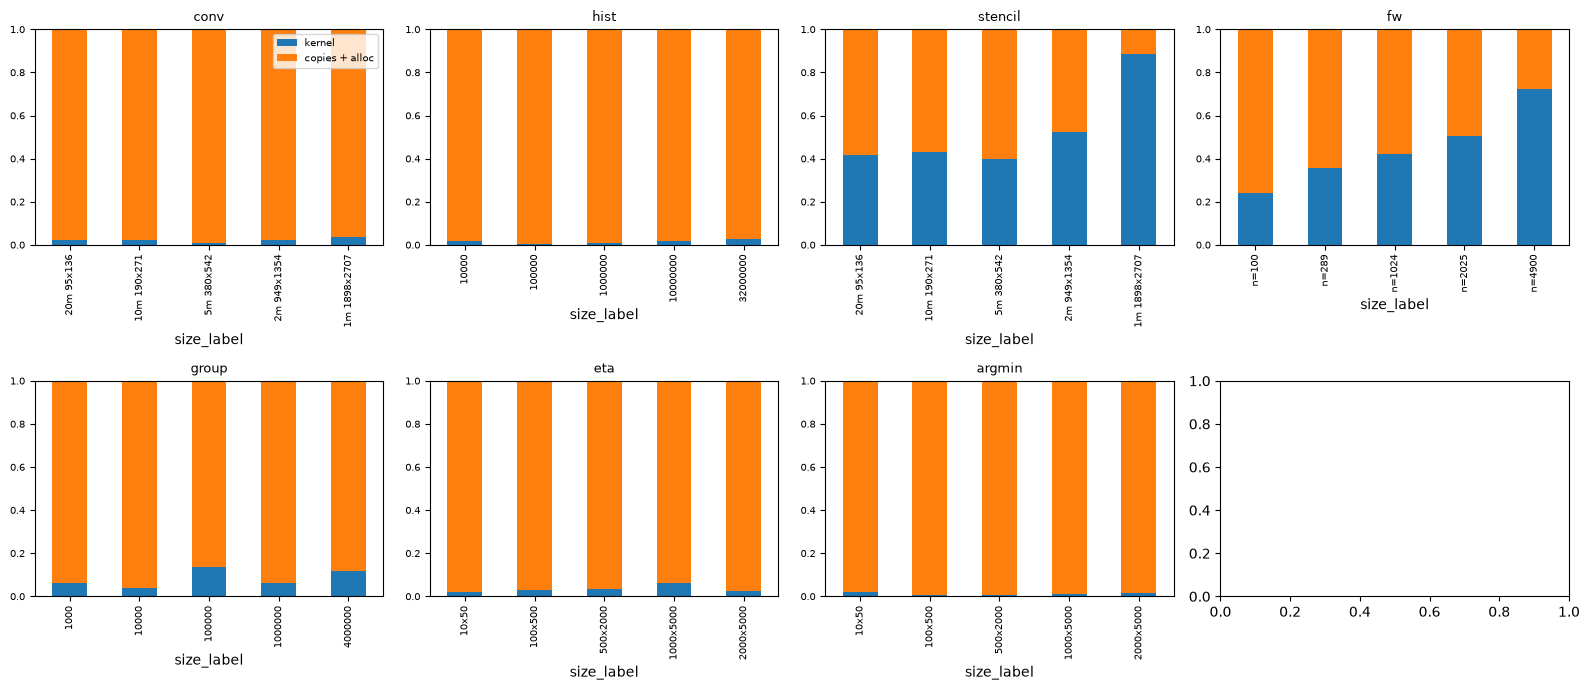

In [4]:
fig, axes = plt.subplots(2, (len(APPS) + 1) // 2, figsize=(4 * ((len(APPS) + 1) // 2), 7))
for ax, app in zip(axes.flat, APPS):
    m = med[(med.app == app) & (med.machine == GPU_MACHINE)]
    k = m[m.version == 'gpu_kernel'].set_index('size_label')['median']
    e = m[m.version == 'gpu_e2e'].set_index('size_label')['median']
    order = m[m.version == 'gpu_e2e'].sort_values('size').size_label
    share = pd.DataFrame({'kernel': (k / e)[order], 'copies + alloc': (1 - k / e)[order]})
    share.plot.bar(stacked=True, ax=ax, legend=False, fontsize=7)
    ax.set_title(app, fontsize=9); ax.set_ylim(0, 1)
axes.flat[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig('../results/copy_share.png', dpi=150)

## Thread-count sweep (laptop)
Run the laptop bench with `--threads 1,2,4,8,14,20` to fill this plot.

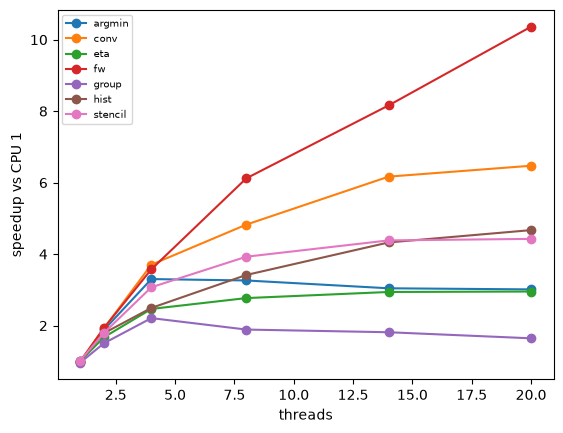

In [5]:
s = med[(med.machine == CPU_MACHINE) & (med.version == 'cpuN')]
largest = s.groupby('app')['size'].transform('max')
s = s[s['size'] == largest]
for app, g in s.groupby('app'):
    one = med[(med.machine == CPU_MACHINE) & (med.app == app) & (med.version == 'cpu1') &
              (med['size'] == g['size'].iloc[0])]['median'].iloc[0]
    g = g.sort_values('threads')
    plt.plot(g.threads, one / g['median'], 'o-', label=app)
plt.xlabel('threads'); plt.ylabel('speedup vs CPU 1'); plt.legend(fontsize=7)
plt.savefig('../results/thread_sweep.png', dpi=150)

## AoS vs SoA (application eta): effective bandwidth
Useful bytes per order x courier pair: freeNode 4 + freeAtMs 8 + one table entry 4 + the output 4 = 20 bytes.

In [6]:
m = med[(med.app == 'eta') & (med.machine == GPU_MACHINE) & med.version.isin(['gpu_kernel', 'gpu_aos_kernel'])]
bw = m.assign(GBps=20 * m['size'] / (m['median'] / 1000) / 1e9)
bw.pivot(index='size_label', columns='version', values='GBps').round(1)

version,gpu_aos_kernel,gpu_kernel
size_label,,
1000x5000,213.9,292.9
100x500,62.9,50.0
10x50,1.0,0.9
2000x5000,227.8,300.7
500x2000,232.6,250.3


## Roofline (RTX 3060 Laptop: 3840 CUDA cores x 2 FLOP x 2.1 GHz = 16.1 TFLOP/s FP32; 192-bit GDDR6 at 14 Gbps = 336 GB/s)
FLOP and byte counts per kernel, derived from the code (write the derivation in the report). Achieved performance uses the kernel time at the largest size.

,app,FLOP/byte,FLOP/s
0,conv,6.250000,9.539335e+11
1,hist,0.750000,1.539448e+11
2,stencil,0.500000,1.457923e+10
3,fw,4.000000,4.358253e+11
4,group,10.666667,4.528769e+11
5,eta,0.600000,1.804376e+11
6,argmin,0.500000,1.173021e+11


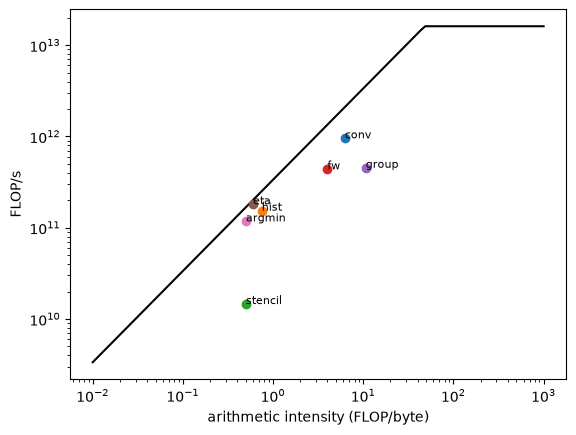

In [7]:
PEAK_FLOPS, PEAK_BW = 2 * 3840 * 2.1e9, 336e9
def counts(app, size):
    n = size
    if app == 'fw':
        N = int(np.ceil(n / 32) * 32)
        return 2 * N ** 3, (N // 32) * N * N * 4 * 4
    if app == 'eta': return 12 * n, 20 * n
    if app == 'argmin': return 2 * n, 4 * n
    if app == 'hist': return 3 * n, 4 * n
    if app == 'group': return 2 * 64 * n, 12 * n
    if app == 'conv': return 2 * 25 * n, 8 * n
    if app == 'stencil': return 100 * 6 * n, 100 * 12 * n
    return np.nan, np.nan
pts = []
for app in APPS:
    m = med[(med.app == app) & (med.machine == GPU_MACHINE) & (med.version == 'gpu_kernel')]
    if not len(m): continue
    r = m.sort_values('size').iloc[-1]
    flops, bytes_ = counts(app, r['size'])
    pts.append((app, flops / bytes_, flops / (r['median'] / 1000)))
ai = np.logspace(-2, 3, 100)
plt.loglog(ai, np.minimum(PEAK_FLOPS, ai * PEAK_BW), 'k-')
for app, x, y in pts:
    plt.loglog(x, y, 'o'); plt.annotate(app, (x, y), fontsize=8)
plt.xlabel('arithmetic intensity (FLOP/byte)'); plt.ylabel('FLOP/s')
plt.savefig('../results/roofline.png', dpi=150)
pd.DataFrame(pts, columns=['app', 'FLOP/byte', 'FLOP/s'])

## Effect on the whole simulation

In [8]:
sims = pd.concat([pd.read_csv(f) for f in glob.glob('../results/sim_*.csv')], ignore_index=True)
sims

ValueError: No objects to concatenate